# Chess Rating Volatility Analysis
### Exploring age, activity, and K-factor using FIDE rating data

**Group Name: Forking Cooked** <br>
**Group Members:**
- Eng Cheng Xin
- Koh Lin Kiat
- Lew Wai Loon
- Wong E Shen
- Zhou Qian Li

## Introduction

**The popularity of chess has been rising in recent years.**

Some key drivers of this surge were boredom during the COVID-19 lockdown, successful online platforms such as Twitch, celebrity endorsements, and Netflix's The Queen's Gambit, which has helped make chess one of the fastest-growing games in the world (Ruth, 2026). The United Nations estimates that 605 million adults play the game regularly, and much of its recent rise has been driven by young people. (Rust, 2026).

A common term in competitive chess is “Elo,” which refers to a player’s chess rating and is represented as rating in the dataset. It serves as an estimate of a player’s playing strength relative to others. When a player performs better than expected, their Elo increases; when they perform worse than expected, it decreases. One factor that determines how much a player’s rating changes after each game is the K-value, or development coefficient, represented as k in the dataset. In general, a higher K-value means the rating changes more quickly, while a lower K-value makes rating changes smaller.

Beyond viewing rating solely as a measure of playing strength, our group is interested in understanding how players progress over time. To explore this, we focus on rating volatility, namely how much a player’s rating changes over time. In particular, we examine the following question of interest:

> **How does player age relate to rating volatility, and what factors explain the observed differences across age groups?**

To investigate this, we analyse the August and September 2025 chess player rating data from TidyTuesday, originally sourced from FIDE, the International Chess Federation.

The dataset consists of 12 variables, which are *id*, *name*, *title*, *fed*, *sex*, *title*, *wtitle*, *otitle*, *foa*, *rating*, *games*, *k*, and *bday*.

### Data Dictionary for both months (August and September)
|variable |class     |description                           |
|:--------|:---------|:-------------------------------------|
|id       |integer   |Identification number of a player within FIDE database. |
|name     |character |Player name. |
|fed      |character |Federation of player. Similar, but not identical to, IOC country codes. An unofficial list is available [here](https://www.mark-weeks.com/aboutcom/mw15b16.htm) |
|sex      |character |Sex of player (M - male, F - female) |
|title    |character |Title of a player (GM - Grand Master, WGM - Woman Grand Master, IM - International Master, WIM - Woman International Master, FM - FIDE Master, WFM - Woman FIDE Master, CM - Candidate Master, WCM - Woman Candidate Master) |
|wtitle   |character |Woman title of a player (WGM - Woman Grand Master, WIM - Woman International Master, WFM - Woman FIDE Master, WCM - Woman Candidate Master) |
|otitle   |character |Comma-separated list. Other titles of a player (IA - International Arbiter, FA - FIDE Arbiter, NA - National Arbiter, IO - International Organizer, FT - FIDE Trainer, FST - FIDE Senior Trainer, DI - Developmental Instructor, NI - National Instructor) |
|foa      |character |FIDE Online Arena title of a player (AGM - Arena Grand Master, AIM - Arena International Master, AFM - Arena FIDE Master, ACM - Arena Candidate Master) |
|rating   |integer   |Standard chess rating (Elo). |
|games    |integer   |Number of games played in the month. |
|k        |integer   |Rating K factor (Value influencing how much a player's rating changes after a game) |
|bday     |integer   |Year of birth of a player. |


## Data Cleaning and Summary

Our group first conducted data cleaning processes such as null and duplicate value checking and data transformations.


The two monthly datasets were merged on both `id` and `name`, as duplicate `id` values were found across both August and September datasets — merging on `id` alone would have produced incorrect matches. An inner join was used to retain only players appearing in both months, ensuring rating comparisons were made on consistently matched individuals. Following the merge, several new variables were created:
- `rating_change` (September rating minus August rating)
- `age` (2025 minus birth year)
- `rating_group` (bucketed into five intervals: <1600, 1600–1800, 1800–2000, 2000–2200, 2200+)
- `age_group` (under 18 vs. 18 and above).


Players with zero games played in September were excluded, as all such players recorded a rating change of exactly zero — a mechanical outcome of inactivity rather than performance. Retaining them would have artificially compressed the distribution of rating changes and obscured meaningful patterns. After this filter, the dataset contains 37533 active players, with ages ranging from 5 to 97. Among these, the median number of games played in September is 7, the median August rating is 1755, and the median rating change is -1.


The above outlines the key highlights of our exploratory data analysis; the section below provides a more comprehensive view of the full process.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Importing Datasets
fide_ratings_august = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_august.csv')
fide_ratings_september = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_september.csv')

In [3]:
# Checking for id duplication for August

fide_ratings_august["id"].duplicated().sum()
# 32 duplicated occurence

# check if duplicated id values are the same person
dup_aug = fide_ratings_august[fide_ratings_august["id"].duplicated(keep = False)].sort_values('id')
dup_aug.head()
# not same people

,id,name,fed,sex,title,wtitle,otitle,foa,rating,games,k,bday
131118,15010830,"Oquendo, Eddy",FID,M,NaN,NaN,NaN,NaN,1545,0,40,1966
103936,15010830,"Lozanovski, Andrej",MKD,M,NaN,NaN,NaN,NaN,1775,0,40,2007
144218,34310975,"Purle, David",ENG,M,NaN,NaN,NaN,ACM,1573,0,40,2012
135757,34310975,"Pavlenko, Stepan",RUS,M,NaN,NaN,NaN,NaN,1411,0,40,2011
160885,34340637,"Schell, Finn",ENG,M,NaN,NaN,NaN,NaN,1956,7,40,2008


In [4]:
# Checking for id duplication for September

fide_ratings_september["id"].duplicated().sum()
# 35 duplicated occurence

# check if duplicated id values are the same person
dup_sep = fide_ratings_september[fide_ratings_september["id"].duplicated(keep = False)].sort_values('id')
dup_sep.head()
# also not same people

,id,name,fed,sex,title,wtitle,otitle,foa,rating,games,k,bday
137137,34310975,"Pavlenko, Stepan",RUS,M,NaN,NaN,NaN,NaN,1411,0,40,2011
145666,34310975,"Purle, David",ENG,M,NaN,NaN,NaN,ACM,1564,13,40,2012
141953,34340637,"Plotnikov, Aleksandr M",FID,M,NaN,NaN,NaN,NaN,1564,0,40,1988
162555,34340637,"Schell, Finn",ENG,M,NaN,NaN,NaN,NaN,1960,8,40,2008
26039,34345442,"Brown, Gavin",ENG,M,NaN,NaN,NaN,NaN,1774,7,40,1964


In [5]:
# Checking for id and name duplication

fide_ratings_august[["id", "name"]].duplicated().sum()
# 0

fide_ratings_september[["id", "name"]].duplicated().sum()
# 0

np.int64(0)

Although id is intended to identify players, duplicate id values were found within both the August and September datasets. Merging on id alone would therefore create incorrect many-to-many matches. To avoid this, the datasets were merged on both id and name, which provided a more reliable way to align the same player across months.

In [6]:
# Merging both months
df = fide_ratings_august.merge(fide_ratings_september, on=["id", "name"], suffixes=("_aug", "_sep"), how="inner")

An inner join was used to retain only players who appear in both the August and September datasets, ensuring that rating changes could be computed consistently for the same individuals.

In [7]:
# Create rating change
df['rating_change'] = df['rating_sep'] - df['rating_aug']

In [8]:
# Create age
df['age'] = 2025 - df['bday_aug']
df.head(5)

,id,name,fed_aug,sex_aug,title_aug,wtitle_aug,otitle_aug,foa_aug,rating_aug,games_aug,...,title_sep,wtitle_sep,otitle_sep,foa_sep,rating_sep,games_sep,k_sep,bday_sep,rating_change,age
0,53707043,A Darshil,IND,M,NaN,NaN,NaN,NaN,1412,4,...,NaN,NaN,NaN,NaN,1412,0,40,2013,0,12
1,53200465,"A F M Ehteshamul, Hoque (tuhin",BAN,M,NaN,NaN,NaN,NaN,1797,0,...,NaN,NaN,NaN,NaN,1797,0,40,1977,0,48
2,5716365,"A Hamid, Harman",MAS,M,NaN,NaN,NaN,NaN,1552,0,...,NaN,NaN,NaN,NaN,1552,0,20,1970,0,55
3,53200553,A I Sabbir,BAN,M,NaN,NaN,NaN,NaN,1607,0,...,NaN,NaN,NaN,NaN,1607,0,40,1995,0,30
4,5045886,"A K, Kalshyan",IND,M,NaN,NaN,NaN,NaN,1747,0,...,NaN,NaN,NaN,NaN,1747,0,20,1964,0,61


In [9]:
# Create Rating Levels
df['rating_group'] = pd.cut(
    df['rating_aug'],
    bins=[0,1600,1800,2000,2200,3000],
    labels=['<1600','1600-1800','1800-2000','2000-2200','2200+']
)

In [10]:
# Checking if non-active players (games played = 0) have zero rating change

df_zero_games = df[df['games_sep'] == 0]
df_zero_games['rating_change'].value_counts()

,count
rating_change,
0,158427


An examination of players with zero recorded games in September shows that all such players have a rating change of zero. This indicates that inactivity is directly associated with no change in rating. Including these players would artificially compress the variability of rating change and obscure meaningful patterns. Therefore, players with zero games were excluded from subsequent analyses to focus on active players whose rating changes reflect actual performance.

In [11]:
# Checking the age range of active players

df_nonzero_games = df[df["games_sep"] > 0].copy()
print(df_nonzero_games['age'].min())
print(df_nonzero_games['age'].max())

5
97


After restricting the dataset to active players (those with at least one game played in September), the age distribution ranges from 5 to 97 years old.

In [12]:
# Median number of games played for active players

print(f"Median games played in September: {df_nonzero_games['games_sep'].median()}")

Median games played in September: 7.0


In [13]:
# Create age group (< 18 and >= 18)

df_nonzero_games['age_group'] = pd.cut(
    df_nonzero_games['age'],
    bins=[5,18,97],
    labels=['< 18', '>= 18']
)

In [14]:
# Number of active players

print(f"Number of active players: {len(df_nonzero_games)}")
print(f"Median August rating: {df_nonzero_games['rating_aug'].median()}")
print(f"Median rating change: {df_nonzero_games['rating_change'].median()}")

Number of active players: 37533
Median August rating: 1755.0
Median rating change: -1.0


## Visualisations

### Figure 1: Rating Changes of Active Players vs. Age
This figure consists of two subplots, Figure 1A and Figure 1B. Figure 1A shows the relationship between rating change and age for all active players, while Figure 1B presents a subset of Figure 1A restricted to active players who played the median number of games in September, which was 7.

In [15]:
import plotly.graph_objects as go

active = df_nonzero_games
median7 = df_nonzero_games[df_nonzero_games["games_sep"] == 7]

fig = go.Figure()

# Trace 1: All active players
fig.add_trace(go.Scatter(
    x=active["age"],
    y=active["rating_change"],
    mode="markers",
    marker=dict(size=4, opacity=0.4, color="steelblue"),
    name="All Active Players",
    visible=True,
    customdata=active[["name", "rating_aug", "games_sep"]].values,
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Age: %{x}<br>"
        "Rating Change: %{y}<br>"
        "August Rating: %{customdata[1]}<br>"
        "Games Played: %{customdata[2]}"
        "<extra></extra>"
    )
))

# Trace 2: Median games players
fig.add_trace(go.Scatter(
    x=median7["age"],
    y=median7["rating_change"],
    mode="markers",
    marker=dict(size=4, opacity=0.4, color="coral"),
    name="Games Played = 7 (Median)",
    visible=False,
    customdata=median7[["name", "rating_aug", "games_sep"]].values,
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Age: %{x}<br>"
        "Rating Change: %{y}<br>"
        "August Rating: %{customdata[1]}<br>"
        "Games Played: %{customdata[2]}"
        "<extra></extra>"
    )
))

# Vertical line at age 18
fig.add_vline(x=18, line_color="red", line_width=1.5,
              annotation_text="Age = 18", annotation_position="top right")

fig.update_layout(
    title={
      "text": "<b>Figure 1: Rating Change of Active Players vs Age</b>",
      "x": 0.5,
      "xanchor": "center"},
    xaxis_title="Age",
    yaxis_title="Rating Change",
    updatemenus=[dict(
        buttons=[
            dict(label="Figure 1A: All Active Players",
                 method="update",
                 args=[{"visible": [True, False]}]),
            dict(label="Figure 1B: Games Played = 7 (Median)",
                 method="update",
                 args=[{"visible": [False, True]}])
        ],
        direction="down",
        showactive=True,
        x=0.01,
        xanchor="left",
        y=1.11,
        yanchor="top"
    )]
)

fig.show(renderer="colab")

Figure 1A shows a strong age-related pattern in rating volatility:
> younger players display much wider month-to-month rating changes than older players.


To test whether this is mainly due to differences in activity level, we use an interactive scatterplot with a dropdown menu that switches between all active players and players who played exactly 7 games in September, the median number of games played, referred to as Figure 1B.

In both views, the same general trend is visible:

> younger players remain much more variable, while older players stay more tightly clustered around zero.

This indicates that the number of games played is unlikely to be the main explanation for the higher volatility observed among youth players. Instead, other structural features of the player pool or the rating system are likely to play a more important role.

### Figure 2: Distribution of Rating Change across K-values (players who played 7 games)
To further investigate why younger players exhibit greater month-to-month rating volatility, we examined the role of the **K-value**, which FIDE defines as the development coefficient in the rating formula. Only players who played the median number of games, which is 7 games, were retained, in order to control for the influence of differences in the number of games played.

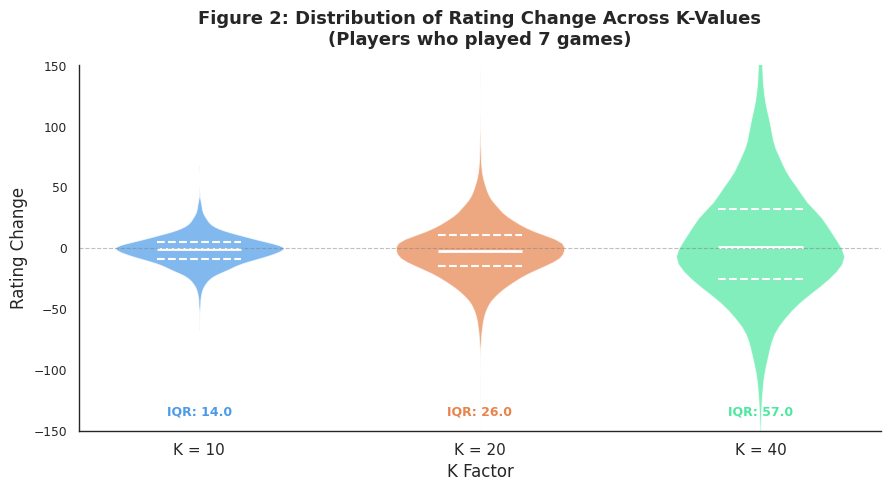

In [16]:
sns.set_theme(style="white", context="paper")

fig, ax = plt.subplots(figsize=(9, 5))

colors = ["#4C9BE8", "#E8834C", "#4CE8A0"]

parts = ax.violinplot(
    [df_nonzero_games[df_nonzero_games["k_aug"] == k]["rating_change"].values
     for k in [10, 20, 40]],
    positions=[1, 2, 3],
    widths=0.6,
    showmedians=True,
    showextrema=False,
    quantiles=[[0.25, 0.75], [0.25, 0.75], [0.25, 0.75]]
)

for i, (pc, color) in enumerate(zip(parts["bodies"], colors)):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
    pc.set_edgecolor("white")

parts["cmedians"].set_color("white")
parts["cmedians"].set_linewidth(2)

parts["cquantiles"].set_color("white")
parts["cquantiles"].set_linewidth(1.5)
parts["cquantiles"].set_linestyle("--")

for i, k in enumerate([10, 20, 40]):
    subset = df_nonzero_games[df_nonzero_games["k_aug"] == k]["rating_change"]
    q1, q3 = subset.quantile(0.25), subset.quantile(0.75)
    ax.annotate(f"IQR: {q3-q1:.1f}", xy=(i+1, -140),
                ha="center", va="bottom", fontsize=9,
                color=colors[i], fontweight="bold")

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["K = 10", "K = 20", "K = 40"], fontsize=11)
ax.set_xlabel("K Factor", fontsize=12)
ax.set_ylabel("Rating Change", fontsize=12)
ax.set_title("Figure 2: Distribution of Rating Change Across K-Values\n(Players who played 7 games)",
             fontsize=13, fontweight="bold", pad=15)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--", alpha=0.5)
ax.set_ylim(-150, 150)
sns.despine()

plt.tight_layout()
plt.show()

Figure 2 shows that
> K-value is an important driver to the amount of rating change.

As seen in the figure, the spread of rating change is the highest when k = 40, followed by k = 20, and lastly k = 10, showing a positive relationship between rating volatility and k-value.

### Figure 3: Share of Active Players in each K-value Category by Age Group
Figure 2 has established the significance of the K-value in driving the magnitude of rating changes, with higher K-values associated with greater volatility.

We now determine how many under-18 players fall into categories with higher K-values, to assess whether their concentration in these groups helps explain the greater variability observed among younger players.


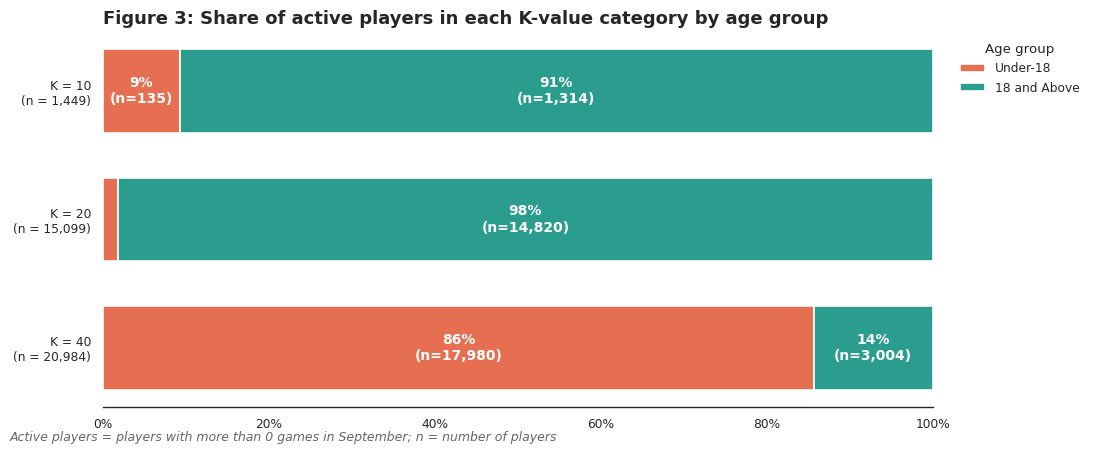

In [17]:
sns.set_theme(style="white", context="paper")

tab = pd.crosstab(df_nonzero_games["k_aug"], df_nonzero_games["age_group"]).reindex([10, 20, 40])
tab = tab.fillna(0).astype(int)

shares = tab.div(tab.sum(axis=1), axis=0)

age_groups = ["< 18", ">= 18"]
label_map = {"< 18": "Under-18", ">= 18": "18 and Above"}
palette = {"< 18": "#e76f51", ">= 18": "#2a9d8f"}

fig, ax = plt.subplots(figsize=(11, 4.5))

y = np.arange(len(tab))
left = np.zeros(len(tab))

for group in age_groups:
    values = shares[group].values
    counts = tab[group].values

    ax.barh(
        y,
        values,
        left=left,
        label=label_map[group],
        color=palette[group],
        edgecolor="white",
        linewidth=1.2,
        height=0.65
    )

    for i in range(len(values)):
        if values[i] > 0.05:
            ax.text(
                left[i] + values[i] / 2,
                y[i],
                f"{values[i]*100:.0f}%\n(n={counts[i]:,})",
                ha="center",
                va="center",
                fontsize=10,
                color="white",
                fontweight="bold"
            )

    left += values

ax.set_yticks(y)
ax.set_yticklabels([f"K = {k}\n(n = {n:,})" for k, n in zip(tab.index, tab.sum(axis=1))])
ax.invert_yaxis()

ax.set_xlim(0, 1)
ticks = np.linspace(0, 1, 6)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{int(t*100)}%" for t in ticks])

ax.set_title(
    "Figure 3: Share of active players in each K-value category by age group",
    fontsize=13,
    fontweight="bold",
    loc="left"
)

ax.legend(title="Age group", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine(ax=ax, left=True)
ax.tick_params(left=False)

fig.text(
    0.01, 0.01,
    "Active players = players with more than 0 games in September; n = number of players",
    fontsize=9, color="0.4", style="italic"
)

plt.tight_layout()
plt.show()


Figure 3 presents the share of active players in each K-value category by age group. Each bar is split by age, showing how under-18 players and adults are distributed across K = 10, 20, and 40.

It shows that players with K = 40 are overwhelmingly under 18, while players with K = 20 and K = 10 are predominantly adults. The figure therefore suggests that:
> the greater volatility among under-18 players is not mainly due to activity levels, but partly because many of them are in the high-K segment of the rating system.

## Final Discussion
Based on our results, the month-to-month rating volatility among the under-18 players is mostly a structural feature of the FIDE rating system rather than a behavioural one. Our initial hypothesis that younger players experience greater rating change variation because they play more is invalid, as shown in Figure 1B. This aligns with what a player on Chess.com pointed out: one speaker said that a rating uses past performance to predict future performance, so a 1500 is essentially a 1500 regardless of games played (Chess.com, 2021). Playing more games should not, on its own, push a rating up or down, which is consistent with what we found.

​Instead, the K-factor appears to be the main driver, a view well established in the chess community as well. Figure 2 showed that the rating change distribution widens as K increases, and Figure 3 showed that K = 40 players are overwhelmingly under 18. This is consistent with FIDE’s rules, which assign K = 40 to new players and to players up to the end of the year of their 18th birthday if their rating is below 2300, K = 20 to players rated below 2400, and K = 10 once a player has reached 2400 (FIDE, 2024). Furthermore, according to Royal Chess Mall’s guide, newer players typically have a higher K-factor, allowing for faster rating adjustments as they learn and improve (Royal Chess Mall, 2024). Given the popularity of chess amongst youths, it is unsurprising that we see wider rating adjustments among under-18s.

​However, we must remember that correlation is not causation, and there are limits to what we can claim here. We examined only one month-to-month transition, so we cannot speak to longer-term dynamics or rule out other age-related factors, such as genuine skill development. Nonetheless, our analysis suggests that the greater variability among younger players is likely driven by their concentration in the higher-K-factor bracket, and further work is needed to fully disentangle the structural features of the rating system from the developmental patterns of youth players.


## Contributions:
**Lin Kiat**
- Conducted explanatory data analysis relating rating changes to games played during the planning stage. Plotted Figure 3 in Google Colab, helped shape the overall direction of the analysis, drafted the general structure of the writeup and wrote the final discussion. Also provided supporting sources to strengthen the writeups.

**Cheng Xin**
- Conducted exploratory data analysis to examine the relationships between K-value and other variables, including age, rating change, and starting August rating, which informed the development of Figure 2 and its accompanying write-up. Developed and refined an interim version of Figure 1 to better reveal meaningful patterns as part of the figure development process. Constructed a summary of the group’s data cleaning and exploratory data analysis findings, while refining the overall report content and structure.

**Wai Loon**
- Conducted data cleaning, dataset merging, and exploratory data analysis on variables such as age, gender, titles, federation, games played, and rating change. Resolved duplicate-ID merge issues, created derived variables including age and rating change, and filtered out inactive players and unrealistic age values. Assessed the suitability of different variables for the main analysis, and contributed to writing and refining the EDA code and accompanying interpretations. Contributed to the development of the finalised Figure 1.

**E Shen**
- Conducted exploratory analysis to assess and remove less informative variables, particularly titles and FOA, during the early stages of the project. Researched the K-value mechanism in the FIDE rating system and helped interpret its role in explaining age-related rating volatility. Drafted and refined the figure-by-figure discussion and helped connect the three visualisations into a coherent overall explanation to support our final conclusion.

**Qian Li**
- Conducted exploratory data analysis and developed the main research question for the project. Cleaned and merged the August and September datasets, and computed key variables such as rating change. Performed correlation analysis to identify potential relationships between player activity, skill level, and rating changes. Formulated the analytical framework, including hypotheses and case interpretations. Generated key visualizations and used them as the basis for reference and discussion, interpreting patterns in player activity, skill level, and rating volatility to support the insights presented in the report.

## References
Data Science Learning Community. (2025). FIDE chess player ratings [Data set]. TidyTuesday. https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-23/readme.md
<br>
<br>
<br>
FIDE. (2024). FIDE rating regulations. FIDE Handbook. https://handbook.fide.com/chapter/B022024
<br>
<br>
<br>
Royal Chess Mall (2024, July 12). Chess Ranking System: Everything you Need to Know. Royal Chess Mall. https://royalchessmall.com/en-sg/blogs/blog/chess-ranking-system?srsltid=AfmBOor4ojY9mJaKy4fSIiAwsQcuBDQIOPTv9iiVgMKGR1OUfzLngCMC
<br>
<br>
<br>
Rust, S. (2026, February 22). Chess used to be for nerds - now everybody wants in. https://www.bbc.com/news/articles/czx4y194d6eo
<br>
<br>
<br>
Viznik. (2021, June 10). Is ELO related more to skill or the amount of games you’ve played? [Online forum post]. Chess.com. https://www.chess.com/forum/view/general/is-elo-related-more-to-skill-or-the-amount-of-games-youve-played


